In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D, Dropout
import numpy as np

In [3]:
train_dir = r"C:\Users\AMINU\Desktop\EJAZTECH.AI\Image Classification Data\Animal Images for Transfer Learning\train"
val_dir = r"C:\Users\AMINU\Desktop\EJAZTECH.AI\Image Classification Data\Animal Images for Transfer Learning\valid"
test_dir = r"C:\Users\AMINU\Desktop\EJAZTECH.AI\Image Classification Data\Animal Images for Transfer Learning\test"

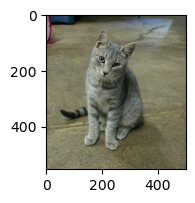

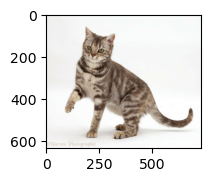

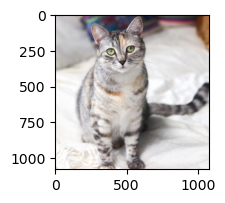

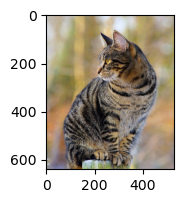

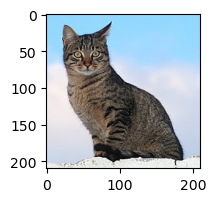

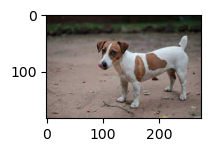

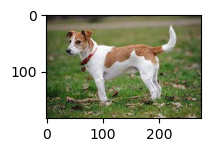

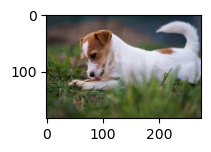

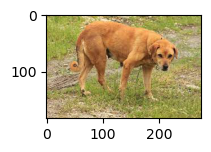

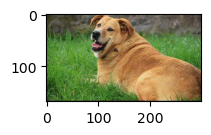

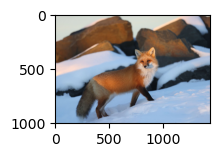

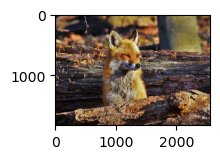

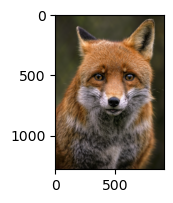

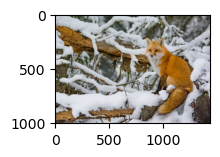

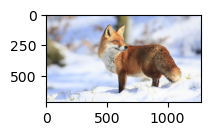

In [4]:
for folder in os.listdir(train_dir):
    folder_path = os.path.join(train_dir, folder)
    image_count = 0
    for file in os.listdir(folder_path):
        image_path = os.path.join(folder_path,file)
        plt.figure(figsize=(2,2))
        plt.imshow(plt.imread(image_path))
        plt.show()
        image_count += 1
        if image_count == 5:
            break

In [5]:
class_labels = [entry for entry in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, entry))]

print("class labels:")
for label in class_labels:
    label_path = os.path.join(train_dir, label)
    num_contents = len(os.listdir(label_path))
    print(f"{label}: {num_contents} items")

class labels:
cat: 80 items
dog: 80 items
fox: 80 items


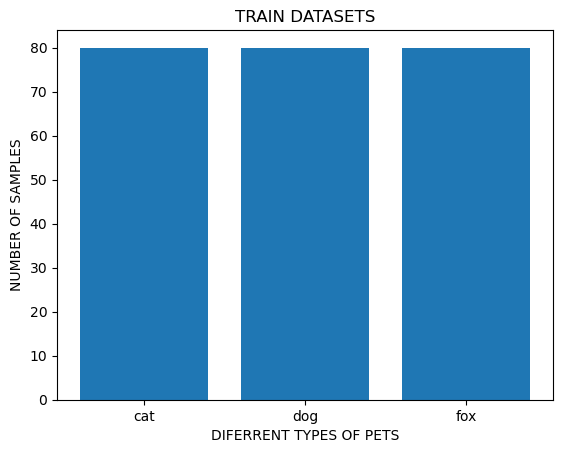

In [6]:
train_image_count_dict = {}
for folder in os.listdir(train_dir):
    folder_path = os.path.join(train_dir, folder)
    train_image_count = 0
    for file in os.listdir(folder_path):
        train_image_count += 1
    train_image_count_dict[folder] = train_image_count
train_subfolders = list(train_image_count_dict.keys())
train_image_counts = list(train_image_count_dict.values())
plt.bar(train_subfolders, train_image_counts)
plt.xlabel("DIFERRENT TYPES OF PETS")
plt.ylabel("NUMBER OF SAMPLES")
plt.title("TRAIN DATASETS")
plt.show()

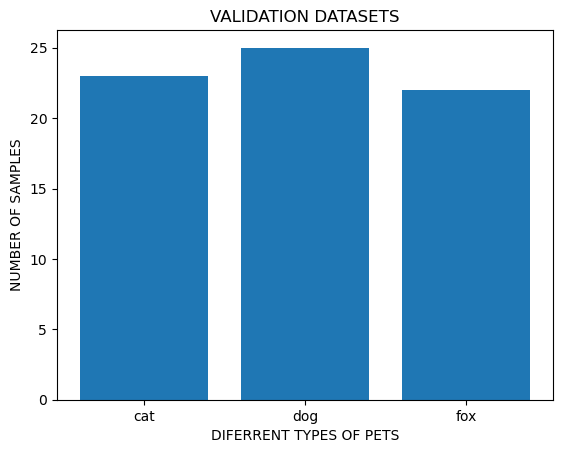

In [7]:
val_image_count_dict = {}
for folder in os.listdir(val_dir):
    folder_path = os.path.join(val_dir, folder)
    val_image_count = 0
    for file in os.listdir(folder_path):
        val_image_count += 1
    val_image_count_dict[folder] = val_image_count
val_subfolders = list(val_image_count_dict.keys())
val_image_counts = list(val_image_count_dict.values())
plt.bar(val_subfolders, val_image_counts)
plt.xlabel("DIFERRENT TYPES OF PETS")
plt.ylabel("NUMBER OF SAMPLES")
plt.title("VALIDATION DATASETS")
plt.show()

In [8]:
data_aug = tf.keras.preprocessing.image.ImageDataGenerator(rescale = 1./225,
                                                           width_shift_range = 20,
                                                           height_shift_range = 20,
                                                           rotation_range = 20,
                                                           horizontal_flip = True,
                                                           vertical_flip = True,
                                                           shear_range = 0.2,
                                                           zoom_range = 0.2)
data = tf.keras.preprocessing.image.ImageDataGenerator(rescale = 1./225)

In [23]:
train_dataset = data_aug.flow_from_directory(train_dir,
                                             subset = "training",
                                             target_size = (224, 224),
                                             seed = 42,
                                             batch_size = 32)
val_dataset = data.flow_from_directory(val_dir,
                                       target_size = (224, 224),
                                       batch_size = 32,
                                       seed = 42)
test_dataset = data.flow_from_directory(test_dir,
                                        target_size = (224, 224),
                                        class_mode = "categorical",
                                        batch_size = 32,
                                        seed = 42)                                        

Found 238 images belonging to 3 classes.
Found 70 images belonging to 3 classes.
Found 0 images belonging to 0 classes.


In [24]:
image_size = (224, 224)
image_shape = image_size + (3,)
mobilenet = tf.keras.applications.MobileNetV2(input_shape = image_shape,
                                              include_top = False,
                                              weights = None)

In [25]:
mobilenet.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [26]:
mobilenet.trainable = False
mobilenet.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
model = Sequential()
model.add(mobilenet)
model.add(GlobalAveragePooling2D())
model.add(Flatten())
model.add(Dense(128, "relu"))
model.add(Dense(110, "relu"))
model.add(Dense(3,  "softmax"))

In [28]:
model.compile(optimizer = "Adam",
              loss = "CategoricalCrossentropy",
              metrics = ["accuracy"])

In [29]:
model.fit(train_dataset, validation_data = val_dataset, epochs = 5)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 473s 59s/step - accuracy: 0.3193 - loss: 1.0991 - val_accuracy: 0.3143 - val_loss: 1.0988
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 379s 51s/step - accuracy: 0.3361 - loss: 1.0987 - val_accuracy: 0.3143 - val_loss: 1.0986
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 394s 53s/step - accuracy: 0.3361 - loss: 1.0987 - val_accuracy: 0.3143 - val_loss: 1.0986
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 313s 41s/step - accuracy: 0.3361 - loss: 1.0987 - val_accuracy: 0.3143 - val_loss: 1.0986
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 259s 33s/step - accuracy: 0.3361 - loss: 1.0986 - val_accuracy: 0.3143 - val_loss: 1.0987


In [30]:
predictions = model.predict(test_dataset)
predicted_labels = np.argmax(predictions, axis = 1)
print(predicted_labels)

ValueError: The PyDataset has length 0

In [41]:
class_labels = [str(i) for i in range(predictions.shape[1])]
for images in test_dataset:
    predictions = model.predict(images)
    predicted_labels = np.argmax(predictions, axis=1)

    for i in range(min(20, len(images))):
        plt.figure(figsize=(2, 2))
        plt.imshow(np.clip(images[i], 0, 1))

        print("Predicted index:", predicted_labels[i]) 

        predicted_label = class_labels[predicted_labels[i]]
        plt.title(f"Predicted label: {predicted_label}")
        plt.show()

NameError: name 'predictions' is not defined